# Mall Customers — Segmentation with K-Means and DBSCAN
Scale the features, choose *k* for K-Means with the elbow method, run DBSCAN on the same scaled data, compare the groupings, and visualize both in 2D with PCA.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score

df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## 1. Select and scale features
`CustomerID` is an identifier and `Gender` is categorical, so clustering uses the three numeric features. StandardScaler puts them on the same scale so no feature dominates the distance calculations.

In [2]:
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pd.DataFrame(X_scaled, columns=features).describe().round(2)

,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.50,-1.74,-1.91
25%,-0.72,-0.73,-0.60
50%,-0.20,0.04,-0.01
75%,0.73,0.67,0.89
max,2.24,2.92,1.89


## 2. K-Means — elbow method

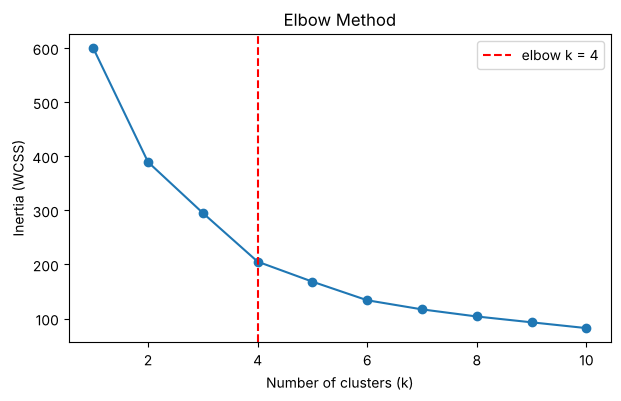

Chosen k: 4


In [3]:
k_range = range(1, 11)
inertia = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)

# Elbow = point farthest from the straight line joining the first and last points
# (both axes normalized to 0-1 so the result does not depend on their units)
k_norm = (np.array(k_range) - min(k_range)) / (max(k_range) - min(k_range))
i_norm = (np.array(inertia) - min(inertia)) / (max(inertia) - min(inertia))
dist = np.abs(k_norm + i_norm - 1) / np.sqrt(2)   # distance to the line from (0,1) to (1,0)
best_k = list(k_range)[int(np.argmax(dist))]

plt.figure(figsize=(7, 4))
plt.plot(k_range, inertia, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'elbow k = {best_k}')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow Method')
plt.legend()
plt.show()
print('Chosen k:', best_k)

Silhouette score as a cross-check on the elbow choice:

In [4]:
for k in range(2, 11):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X_scaled)
    print(k, round(silhouette_score(X_scaled, labels), 3))

2 0.335
3 0.358
4 0.404
5 0.417
6 0.428
7 0.417
8 0.408
9 0.418
10 0.407


In [5]:
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)
df['KMeans_Cluster'].value_counts().sort_index()

KMeans_Cluster
0    65
1    40
2    57
3    38
Name: count, dtype: int64

## 3. DBSCAN
`min_samples` = 2 × number of features = 6. `eps` is read from the k-distance plot (distance to each point's 6th nearest neighbor, sorted): the knee is where distances start rising sharply.

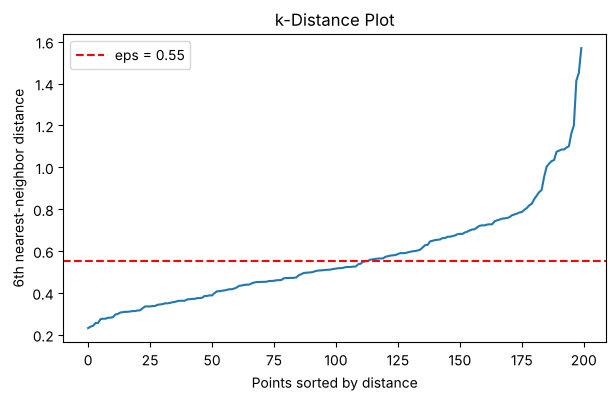

In [6]:
min_samples = 2 * X_scaled.shape[1]
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
distances, _ = nn.kneighbors(X_scaled)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(7, 4))
plt.plot(k_dist)
plt.axhline(0.55, color='red', linestyle='--', label='eps = 0.55')
plt.xlabel('Points sorted by distance')
plt.ylabel(f'{min_samples}th nearest-neighbor distance')
plt.title('k-Distance Plot')
plt.legend()
plt.show()

Quick check of nearby `eps` values (clusters found, noise points, silhouette on non-noise points):

In [7]:
for eps in [0.45, 0.5, 0.55, 0.6, 0.65]:
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
    mask = lab != -1
    n_clusters = len(set(lab[mask]))
    sil = silhouette_score(X_scaled[mask], lab[mask]) if n_clusters > 1 else np.nan
    print(f'eps={eps}: clusters={n_clusters}, noise={(~mask).sum()}, silhouette={sil:.3f}')

eps=0.45: clusters=6, noise=85, silhouette=0.556
eps=0.5: clusters=5, noise=66, silhouette=0.528
eps=0.55: clusters=5, noise=55, silhouette=0.484
eps=0.6: clusters=5, noise=34, silhouette=0.194
eps=0.65: clusters=3, noise=26, silhouette=0.084


In [8]:
eps = 0.55
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)
df['DBSCAN_Cluster'].value_counts().sort_index()   # -1 = noise

DBSCAN_Cluster
-1    55
 0    19
 1    54
 2    29
 3    33
 4    10
Name: count, dtype: int64

## 4. Compare the groupings

In [9]:
db_mask = df['DBSCAN_Cluster'] != -1
summary = pd.DataFrame({
    'Algorithm': ['K-Means', 'DBSCAN'],
    'Clusters': [df['KMeans_Cluster'].nunique(), df.loc[db_mask, 'DBSCAN_Cluster'].nunique()],
    'Noise points': [0, (~db_mask).sum()],
    'Silhouette': [silhouette_score(X_scaled, df['KMeans_Cluster']),
                   silhouette_score(X_scaled[db_mask], df.loc[db_mask, 'DBSCAN_Cluster'])],
})
print(summary.round(3).to_string(index=False))
print('\nNote: DBSCAN silhouette is computed on non-noise points only.')
print('Adjusted Rand Index (K-Means vs DBSCAN, all points):',
      round(adjusted_rand_score(df['KMeans_Cluster'], df['DBSCAN_Cluster']), 3))

Algorithm  Clusters  Noise points  Silhouette
  K-Means         4             0       0.404
   DBSCAN         5            55       0.484

Note: DBSCAN silhouette is computed on non-noise points only.
Adjusted Rand Index (K-Means vs DBSCAN, all points): 0.461


Cross-tab — how K-Means clusters map onto DBSCAN clusters:

In [10]:
pd.crosstab(df['KMeans_Cluster'], df['DBSCAN_Cluster'],
            rownames=['K-Means'], colnames=['DBSCAN (-1 = noise)'])

DBSCAN (-1 = noise),-1,0,1,2,3,4
K-Means,,,,,,
0,17,0,48,0,0,0
1,7,0,0,0,33,0
2,8,19,2,28,0,0
3,23,0,4,1,0,10


Cluster profiles (feature means):

In [11]:
print('K-Means')
display(df.groupby('KMeans_Cluster')[features].mean().round(1).assign(Count=df['KMeans_Cluster'].value_counts()))
print('DBSCAN')
display(df.groupby('DBSCAN_Cluster')[features].mean().round(1).assign(Count=df['DBSCAN_Cluster'].value_counts()))

K-Means


,Age,Annual Income (k$),Spending Score (1-100),Count
KMeans_Cluster,,,,
0,54.0,47.7,40.0,65
1,32.9,86.1,81.5,40
2,25.4,40.0,60.3,57
3,39.4,86.5,19.6,38


DBSCAN


,Age,Annual Income (k$),Spending Score (1-100),Count
DBSCAN_Cluster,,,,
-1,40.2,66.2,29.1,55
0,23.7,26.1,78.3,19
1,53.2,54.4,47.6,54
2,24.5,53.4,50.8,29
3,32.7,81.1,83.0,33
4,44.5,81.1,16.8,10


## 5. PCA to 2 dimensions and visualize

In [12]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print('Explained variance ratio:', pca.explained_variance_ratio_.round(3),
      '| total:', round(pca.explained_variance_ratio_.sum(), 3))

Explained variance ratio: [0.443 0.333] | total: 0.776


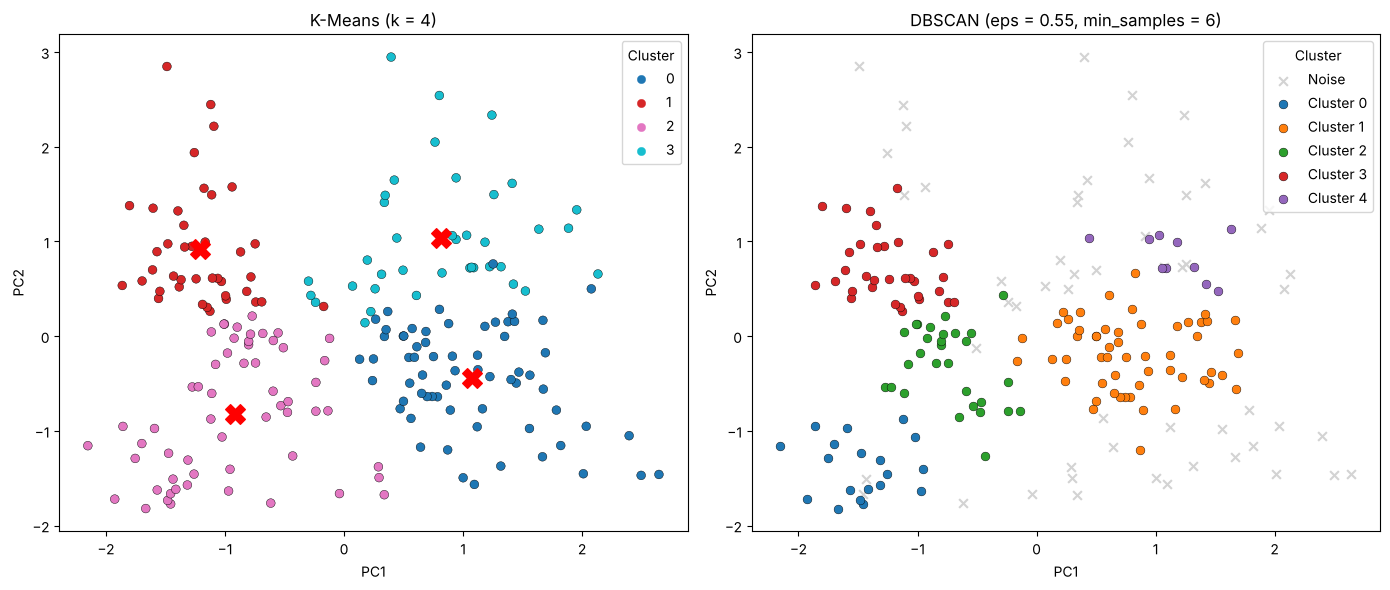

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# K-Means
ax = axes[0]
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=df['KMeans_Cluster'], cmap='tab10', s=40, edgecolor='k', linewidth=0.3)
centers_pca = pca.transform(kmeans.cluster_centers_)
ax.scatter(centers_pca[:, 0], centers_pca[:, 1], c='red', marker='X', s=200, label='Centroids')
ax.set_title(f'K-Means (k = {best_k})')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.legend(*sc.legend_elements(), title='Cluster', loc='upper right')

# DBSCAN
ax = axes[1]
labels = df['DBSCAN_Cluster'].values
for lab in sorted(set(labels)):
    m = labels == lab
    if lab == -1:
        ax.scatter(X_pca[m, 0], X_pca[m, 1], c='lightgray', marker='x', s=40, label='Noise')
    else:
        ax.scatter(X_pca[m, 0], X_pca[m, 1], color=plt.cm.tab10(lab), s=40, edgecolor='k', linewidth=0.3, label=f'Cluster {lab}')
ax.set_title(f'DBSCAN (eps = {eps}, min_samples = {min_samples})')
ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
ax.legend(title='Cluster', loc='upper right')

plt.tight_layout()
plt.show()

## 6. Conclusion

**K-Means (k = 4, from the elbow)** splits every customer into one of four groups:
- older, mid-income, average spenders (~54 yrs)
- younger, high-income, high spenders (~33 yrs)
- young, lower-to-mid income, above-average spenders (~25 yrs)
- high-income, low spenders (~39 yrs)

The silhouette scores keep rising slightly up to k = 6, so the elbow at 4 is the more compact choice; k = 6 would split the mixed groups further.

**DBSCAN (eps = 0.55, min_samples = 6)** finds 5 dense groups and labels 55 customers (27.5%) as noise. It separates the young low-income high spenders (cluster 0) from the young mid-income group, which K-Means merges into one cluster. Its noise points are mostly the high-income and low-income customers on the edges, where the data is sparse.

**Comparison**
- The two methods agree on the main segments: the K-Means high-income/high-spend cluster maps almost entirely to DBSCAN cluster 3, and the older mid-income cluster maps to DBSCAN cluster 1 (ARI = 0.46).
- DBSCAN's silhouette (0.48) is higher than K-Means' (0.40), but only because the 55 hardest-to-assign points are excluded as noise.
- K-Means is the more practical choice for segmentation here, because every customer gets a segment. DBSCAN is useful for flagging outlier customers that don't fit any dense group.
- PCA keeps about 78% of the variance in 2 components, so the 2D plots are a good but not perfect view; some overlap in the plot is separation along the third component.